<a href="https://colab.research.google.com/github/Willortizp75/Willortizp75/blob/main/Proyecto_MachineLearning_WOP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ESPY G6 - Curso: 3 ML Modelos de Regresión con Python**
# **Proyecto de Machine Learning: Estimación de costos de Construcción Residencial**
> ## Autor: ***Wilfrido Ortiz Prieto***

## Contexto del problema ##

La empresa ficticia **Constructora Horizonte S.A.,** dedicada al desarrollo de proyectos residenciales en Costa Rica, desea mejorar la estimación inicial de los costos de construcción de viviendas.

Actualmente, la empresa realiza sus presupuestos mediante el análisis manual de diferentes características de los proyectos, como el área construida, número de habitaciones, baños, cantidad de pisos, nivel de acabados y condiciones del terreno.

La gerencia considera que la aplicación de técnicas de Machine Learning podría contribuir a generar estimaciones preliminares del costo de nuevas construcciones, facilitando la planificación y la toma de decisiones.

Para ello, dispone de un conjunto de datos sintéticos que representa **600 proyectos residenciales independientes**, con información sobre sus principales características y su costo estimado de construcción.

La empresa solicita desarrollar modelos predictivos que permitan estimar el costo total de construcción en colones costarricenses.

## Objetivo del proyecto ##

Construir y comparar diferentes modelos de regresión supervisada para estimar el costo de construcción de viviendas residenciales a partir de sus características físicas y técnicas.

Se utilizarán tres algoritmos: **Regresión Lineal, K-Nearest Neighbors (KNN) y Random Forest.**

El proyecto no contempla series temporales ni pronósticos basados en fechas.

## Parte 1. Carga y exploración de datos (20 puntos)

1. Cargar el dataset proporcionado utilizando Python y pandas.
2. Visualizar los primeros registros del conjunto de datos.
3. Identificar las dimensiones del dataset.
4. Verificar la existencia de valores faltantes, registros duplicados y los tipos de datos.
5. Obtener estadísticas descriptivas de las variables numéricas y revisar las categorías existentes.
6. Identificar cuál es la variable dependiente y cuáles son las variables independientes.
7. Explicar por qué el identificador del proyecto no debe utilizarse como variable predictora.  

**Pregunta de análisis:** ¿Qué información contiene el dataset y qué característica de los proyectos estamos intentando predecir?

In [ ]:
# Cargar librerias
import sklearn

# Tratamiento de Datos
import pandas as pd
import numpy as np

# Gráficos
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
from pathlib import Path

# Preprocesamiento y Modelo
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split,KFold, RepeatedKFold
from sklearn.model_selection import cross_val_score, cross_validate, cross_val_predict
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.feature_selection import SelectKBest, f_regression

# Configuracion de nuestro visuales
plt.rcParams['image.cmap'] = 'bwr'
plt.rcParams['savefig.bbox'] = 'tight'
style.use('ggplot') or plt.style.use('ggplot')

# Ignorar las advertencias de paquetes y sus actualizaciones
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Carga de archivo de datos

datos = pd.read_csv('/content/drive/MyDrive/Datasets/construccion_datos.csv')

# Visualizar los primeros registros del conjunto de datos
datos.head()

,id_proyecto,area_construida_m2,numero_habitaciones,numero_banos,numero_pisos,nivel_acabados,tipo_terreno,complejidad_diseno,acceso_obra,costo_construccion_crc
0,OBRA-0001,163.6,4,2.0,1,Básico,Plano,Baja,Fácil,33237000
1,OBRA-0002,281.3,4,2.0,1,Estándar,Plano,Baja,Fácil,90560000
2,OBRA-0003,285.1,6,3.0,1,Premium,Plano,Media,Intermedio,119998000
3,OBRA-0004,259.6,6,4.0,2,Básico,Plano,Media,Difícil,75370000
4,OBRA-0005,246.8,5,2.0,1,Estándar,Plano,Media,Fácil,88955000


In [ ]:
datos.shape

(600, 10)

In [ ]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_proyecto             600 non-null    object 
 1   area_construida_m2      585 non-null    float64
 2   numero_habitaciones     600 non-null    int64  
 3   numero_banos            582 non-null    float64
 4   numero_pisos            600 non-null    int64  
 5   nivel_acabados          600 non-null    object 
 6   tipo_terreno            585 non-null    object 
 7   complejidad_diseno      600 non-null    object 
 8   acceso_obra             588 non-null    object 
 9   costo_construccion_crc  600 non-null    int64  
dtypes: float64(2), int64(3), object(5)
memory usage: 47.0+ KB


In [ ]:
# Número de valores faltantes o vacíos

datos.isna().sum().sort_values(ascending=False)


,0
numero_banos,18
area_construida_m2,15
tipo_terreno,15
acceso_obra,12
id_proyecto,0
numero_habitaciones,0
nivel_acabados,0
numero_pisos,0
complejidad_diseno,0
costo_construccion_crc,0


In [ ]:
# Registros Duplicados

datos.duplicated().sum()

np.int64(0)

In [ ]:
# Estadísticas descriptivas de las variables

datos.describe()

,area_construida_m2,numero_habitaciones,numero_banos,numero_pisos,costo_construccion_crc
count,585.000000,600.000000,582.000000,600.000000,6.000000e+02
mean,174.179829,3.436667,1.979381,1.440000,6.416956e+07
std,65.139932,1.466142,0.910592,0.616739,2.705788e+07
min,70.400000,1.000000,1.000000,1.000000,2.300000e+07
25%,115.700000,2.000000,1.000000,1.000000,4.198225e+07
50%,170.300000,3.000000,2.000000,1.000000,6.099450e+07
75%,233.500000,5.000000,3.000000,2.000000,8.204450e+07
max,289.000000,6.000000,5.000000,3.000000,1.570910e+08


In [ ]:
# Variables Dependientes e Independientes

variables_independientes = list(datos.columns[:-1])
variable_dependiente = datos.columns[-1]

print("Variables Independientes (X):")
for var in variables_independientes:
    print(f" - {var}")

print("\nVariable Dependiente (Y):")
print(f" - {variable_dependiente}")

Variables Independientes (X):
 - id_proyecto
 - area_construida_m2
 - numero_habitaciones
 - numero_banos
 - numero_pisos
 - nivel_acabados
 - tipo_terreno
 - complejidad_diseno
 - acceso_obra

Variable Dependiente (Y):
 - costo_construccion_crc


## Explicar por qué el identificador del proyecto no debe utilizarse como variable predictora

> El identificador del proyecto es una clave asignada a cada proyecto para fines administrativos.
No debe utilizarse como variable predictora porque no proporciona información física ni técnica acerca de las características de la obra. Si se incorpora al modelo, podría afectar la capacidad de generalización de los algoritmos de Machine Learning.

## ¿Qué información contiene el dataset y qué característica de los proyectos estamos intentando predecir?
> El dataset contiene información de proyectos residenciales independientes. Cada registro representa una construcción y contiene características relacionadas con sus dimensiones, distribución interna, condiciones del terreno, calidad de los acabados, complejidad del diseño y facilidad de acceso a la obra.
Se intenta predecir el costo total de construcción de la vivienda


## Parte 2. Análisis exploratorio y relaciones entre variables (20 puntos)

1. Construir un histograma que represente la distribución de los costos de construcción.
2. Elaborar un gráfico de dispersión entre el área construida y el costo total del proyecto.
3. Construir un diagrama de cajas para comparar los costos según el nivel de acabados.
4. Calcular una matriz de correlación utilizando las variables numéricas.
5. Representar gráficamente las correlaciones mediante un mapa de calor.
6. Identificar al menos dos hallazgos relevantes sobre las relaciones observadas.

**Preguntas de análisis:**
* ¿Cuáles características parecen tener una mayor relación con los costos de construcción?
* ¿Por qué una correlación no necesariamente implica causalidad?

Text(0, 0.5, 'Costo de Construcción (CRC)')

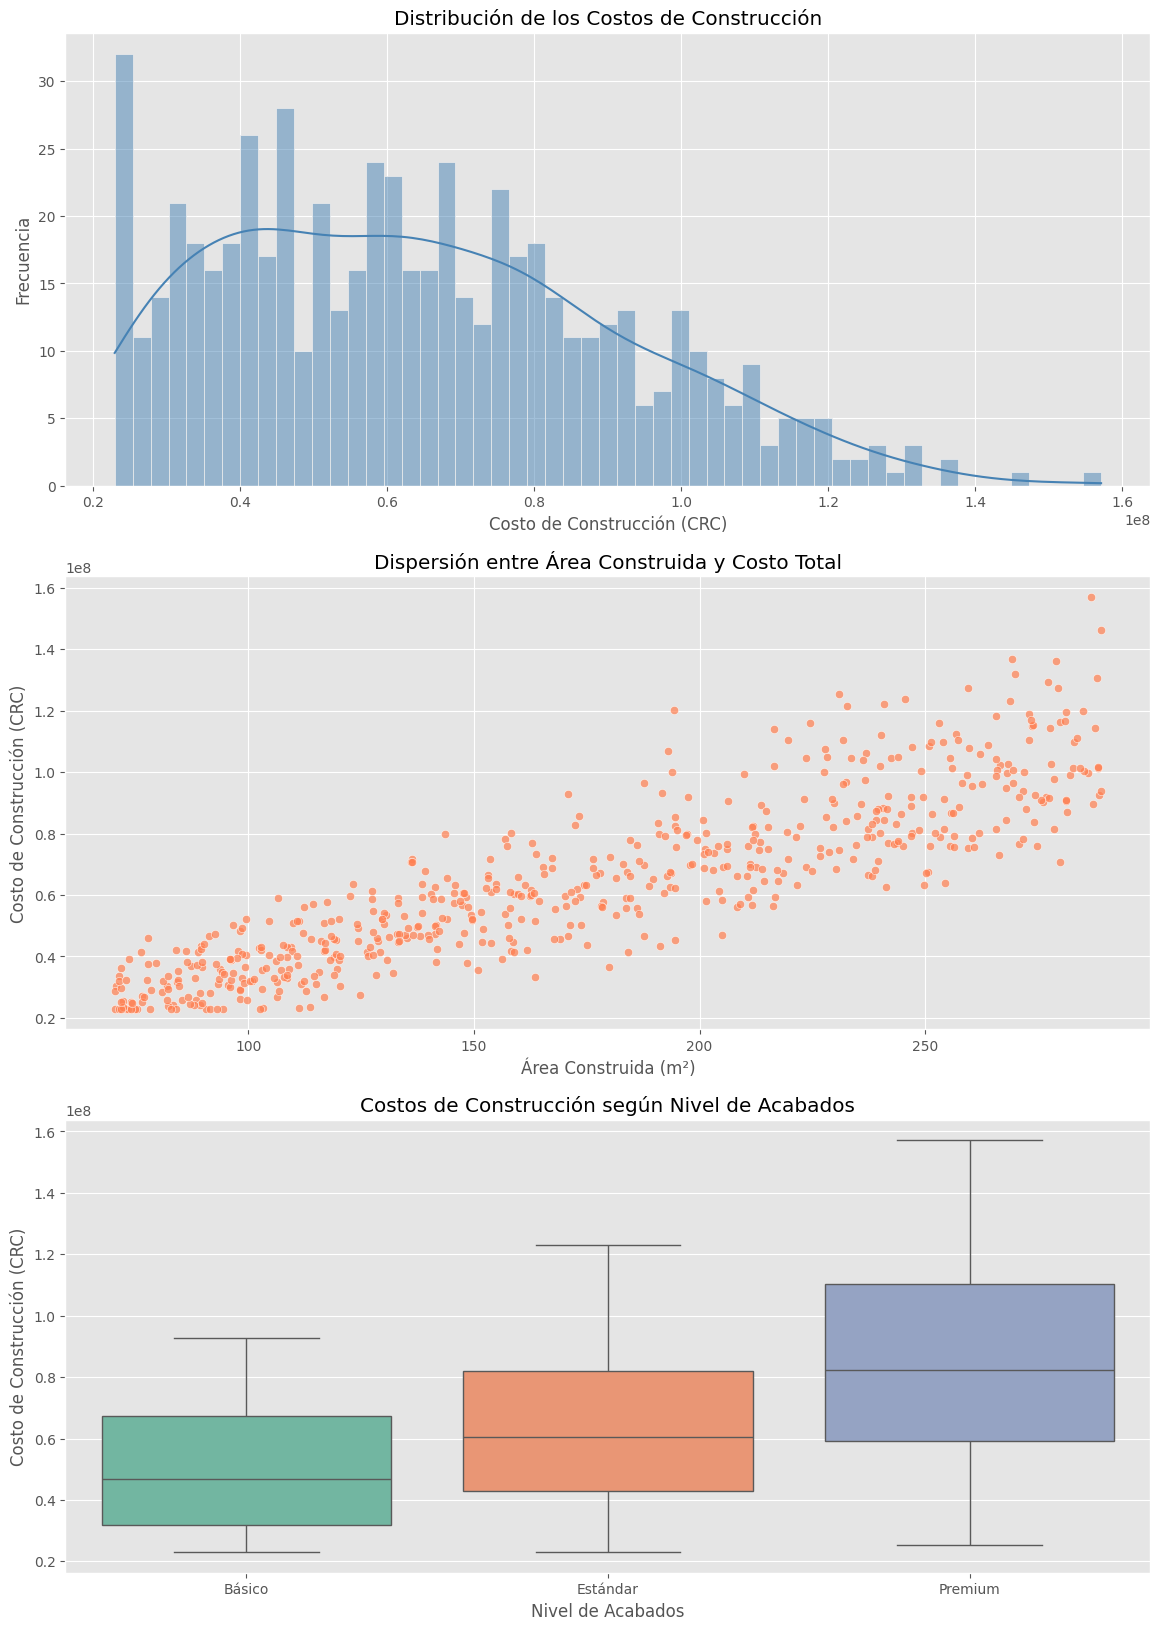

In [ ]:
# Configuración de estilo
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(14, 20))

# 1. Histograma de la distribución de los costos de construcción
sns.histplot(datos['costo_construccion_crc'], kde=True, bins=55, color='steelblue', ax=axes[0])
axes[0].set_title('Distribución de los Costos de Construcción')
axes[0].set_xlabel('Costo de Construcción (CRC)')
axes[0].set_ylabel('Frecuencia')

# 2. Gráfico de dispersión entre el área construida y el costo total
sns.scatterplot(data=datos, x='area_construida_m2', y='costo_construccion_crc', alpha=0.7, ax=axes[1], color='coral')
axes[1].set_title('Dispersión entre Área Construida y Costo Total')
axes[1].set_xlabel('Área Construida (m²)')
axes[1].set_ylabel('Costo de Construcción (CRC)')

# 3. Diagrama de cajas para comparar los costos según el nivel de acabados
sns.boxplot(data=datos, x='nivel_acabados', y='costo_construccion_crc', ax=axes[2], palette='Set2')
axes[2].set_title('Costos de Construcción según Nivel de Acabados')
axes[2].set_xlabel('Nivel de Acabados')
axes[2].set_ylabel('Costo de Construcción (CRC)')

In [ ]:
# 4. Matriz de Correlación para variables numéricas

corr = datos.corr(numeric_only= True).round(2)
print("Matriz de Correlación:")
corr

Matriz de Correlación:


,area_construida_m2,numero_habitaciones,numero_banos,numero_pisos,costo_construccion_crc
area_construida_m2,1.00,0.85,0.63,0.05,0.88
numero_habitaciones,0.85,1.00,0.76,0.03,0.75
numero_banos,0.63,0.76,1.00,-0.05,0.57
numero_pisos,0.05,0.03,-0.05,1.00,0.06
costo_construccion_crc,0.88,0.75,0.57,0.06,1.00


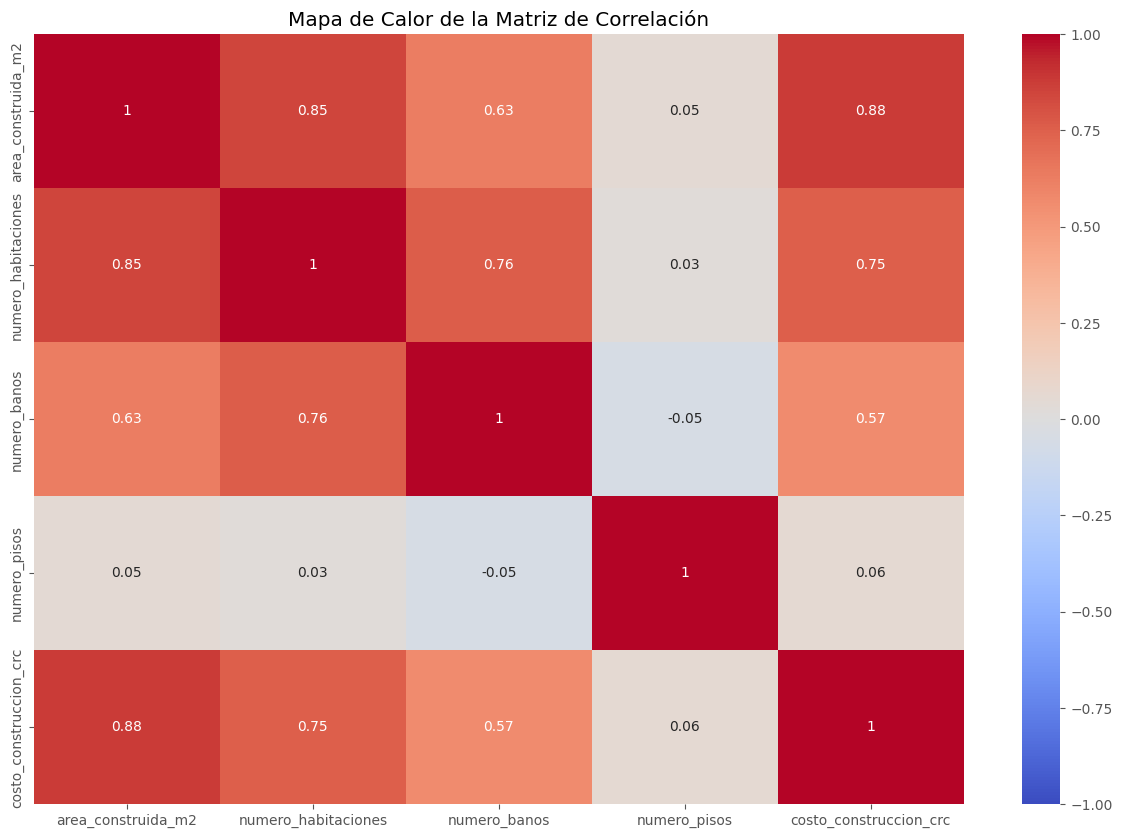

In [ ]:
# 5. Mapa de Calor de la Correlación

fig, ax  =  plt.subplots(figsize = (15,10))
sns.heatmap(corr, annot = True, cmap = 'coolwarm', ax = ax, vmax = 1, vmin = -1)
plt.title('Mapa de Calor de la Matriz de Correlación')
plt.show()

**Preguntas de análisis:**
* **¿Cuáles características parecen tener una mayor relación con los costos de construcción?**  
El área construida y el nivel de acabados muestran la relación más evidente con el costo total de la obra.
* **¿Por qué una correlación no necesariamente implica causalidad?**  
Porque la correlación solo mide la fuerza de la asociación lineal estadística entre dos variables. Puede existir una tercera variable no medida que influya en ambas (confundidora), o la correlación puede ser puramente coincidente (espuria) sin que exista un mecanismo real de causa y efecto.


## Parte 3. Preparación de datos y construcción de modelos (30 puntos)
Dividir los datos utilizando:

* 80 % para entrenamiento.
* 20 % para prueba.
* random_state = 42.

Realizar el preprocesamiento necesario:

* Tratar valores faltantes numéricos mediante la mediana del conjunto de entrenamiento.
* Tratar valores faltantes categóricos mediante la moda del conjunto de entrenamiento.
* Codificar las variables categóricas mediante One-Hot Encoding.
* Aplicar escalamiento a las variables numéricas para KNN.

Los parámetros de preprocesamiento deberán obtenerse exclusivamente del conjunto de entrenamiento, evitando fugas de información hacia el conjunto de prueba.

**Modelo 1. Regresión Lineal**

Entrenar un modelo mediante LinearRegression() para estimar los costos de construcción.

**Modelo 2. K-Nearest Neighbors (KNN)**

Entrenar un modelo utilizando KNeighborsRegressor(n_neighbors=7).

**Modelo 3. Random Forest**

Entrenar un modelo utilizando RandomForestRegressor, con los siguientes parámetros:
* n_estimators = 200
* min_samples_leaf = 2
* random_state = 42

**No es necesario realizar búsqueda de hiperparámetros ni validación cruzada.**

In [ ]:
# Correlacion entre columnas numericas

def matriz_correlacion(corr_mat):
  """ Funcion para Convertir una matriz de correlacion en formato numerica """
  corr_mat = corr_mat.stack().reset_index()
  corr_mat.columns = ['variable 1','variable 2','Correlacion']
  corr_mat = corr_mat.loc[corr_mat['variable 1'] != corr_mat['variable 2'], :]
  corr_mat['Valor Absoluto'] = np.abs(corr_mat['Correlacion'])
  corr_mat = corr_mat.sort_values('Valor Absoluto', ascending = False)

  return(corr_mat)

corr_matrix = datos.select_dtypes(include = ['float','int']).corr(method = 'pearson')
matriz_correlacion(corr_matrix).head(5)

,variable 1,variable 2,Correlacion,Valor Absoluto
4,area_construida_m2,costo_construccion_crc,0.883297,0.883297
20,costo_construccion_crc,area_construida_m2,0.883297,0.883297
5,numero_habitaciones,area_construida_m2,0.848349,0.848349
1,area_construida_m2,numero_habitaciones,0.848349,0.848349
11,numero_banos,numero_habitaciones,0.758753,0.758753


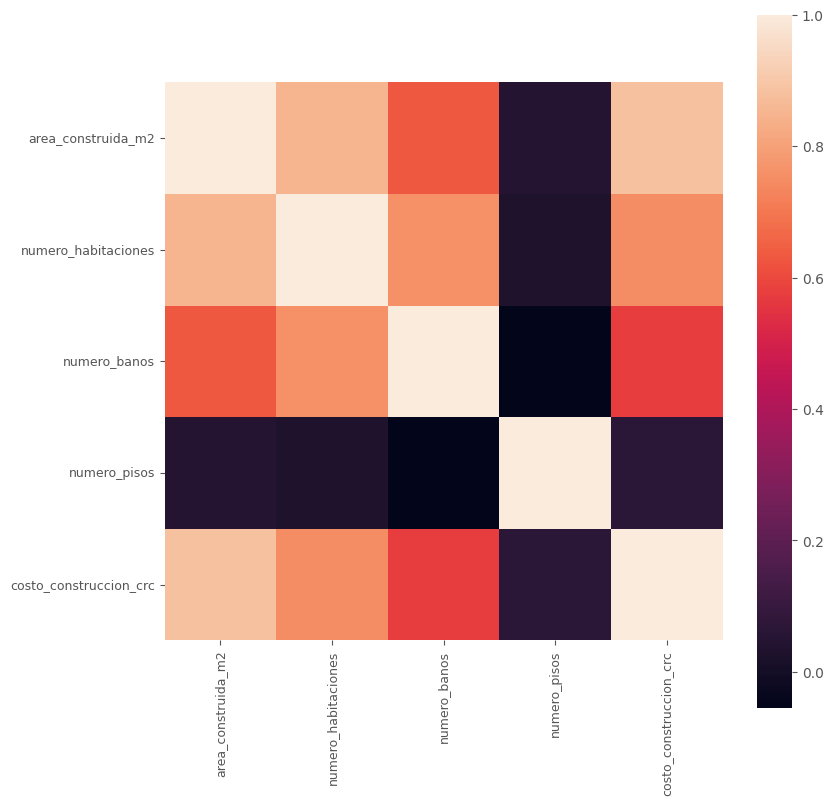

In [ ]:
fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (9,9))

sns.heatmap(
    corr_matrix,
    square = True,
    ax = ax)

ax.tick_params(labelsize = 9)

In [ ]:
# Division de los datos
# 80 % para entrenamiento.
# 20 % para prueba.
# random_state = 42.

# Separar variables independientes (X) y dependiente (y)
X = datos[variables_independientes]
y = datos[variable_dependiente]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y.values.reshape(-1,1),
    test_size = 0.2,
    random_state = 42,
    shuffle = True)

print(f"Dimensiones de Entrenamiento: {X_train.shape}")
print(f"Dimensiones de Prueba: {X_test.shape}")

Dimensiones de Entrenamiento: (480, 9)
Dimensiones de Prueba: (120, 9)


In [ ]:
# Pipeline de Preprocesamiento de los Datos

numeric_cols = X_train.select_dtypes(include=['number']).columns.to_list()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.to_list()

# Valores faltantes numéricos mediante la Mediana → 'StandardScaler'
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Valores faltantes categóricos mediante la Moda → 'OneHotEncoder'
categoricas_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocesamiento = ColumnTransformer(transformers=[
    ('numeric', numeric_transformer, numeric_cols),
    ('cat', categoricas_transformer, cat_cols)
])

preprocesamiento

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['area_construida_m2', 'numero_habitaciones',
                                  'numero_banos', 'numero_pisos']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['id_proyecto', 'nivel_acabados',
                                  'tipo_terreno', 'complejidad_diseno',
                                  'acceso_obra'])])

In [ ]:
# Ajustar SOLO con entrenamiento y aplicar a prueba

X_train_prep = preprocesamiento.fit_transform(X_train)
X_test_prep = preprocesamiento.transform(X_test)

print('Columnas originales:', X_train.shape[1])
print('Columnas después de One-Hot Encoding:', X_train_prep.shape[1])

Columnas originales: 9
Columnas después de One-Hot Encoding: 496


In [ ]:
# Igual que la conversión a DataFrame: ver las columnas transformadas

etiquetas = preprocesamiento.get_feature_names_out()
datos_train_prep = pd.DataFrame(X_train_prep, columns=etiquetas)
datos_train_prep.head()

,numeric__area_construida_m2,numeric__numero_habitaciones,numeric__numero_banos,numeric__numero_pisos,cat__id_proyecto_OBRA-0001,cat__id_proyecto_OBRA-0002,cat__id_proyecto_OBRA-0004,cat__id_proyecto_OBRA-0005,cat__id_proyecto_OBRA-0006,cat__id_proyecto_OBRA-0008,...,cat__nivel_acabados_Premium,cat__tipo_terreno_Pendiente moderada,cat__tipo_terreno_Pendiente pronunciada,cat__tipo_terreno_Plano,cat__complejidad_diseno_Alta,cat__complejidad_diseno_Baja,cat__complejidad_diseno_Media,cat__acceso_obra_Difícil,cat__acceso_obra_Fácil,cat__acceso_obra_Intermedio
0,1.155451,1.069564,0.009222,2.615411,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,-0.128413,-0.295837,-1.097392,-0.696983,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
2,-1.617883,-0.978537,-1.097392,-0.696983,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.985944,1.752264,2.222449,0.959214,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,1.706351,1.752264,1.115836,-0.696983,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [ ]:
# Entrenar Modelo: Regresión Lineal

modelo_lr = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo', LinearRegression())
])

# Entrenar modelo
modelo_lr.fit(X_train, y_train)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['area_construida_m2',
                                                   'numero_habitaciones',
                                                   'numero_banos',
                                                   'numero_pisos']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['id_proyecto',
                                                   'nivel_acabados',
                                                   'tipo_terreno',
                                                   'complejidad_diseno',
                                                   'acceso_obra'])])),
                ('modelo', LinearRegression())])

In [ ]:
# Entrenar Modelo: K-Nearest Neighbors (KNN)

modelo_knn = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo', KNeighborsRegressor(n_neighbors=7))
])

# Entrenar modelo
modelo_knn.fit(X_train, y_train)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['area_construida_m2',
                                                   'numero_habitaciones',
                                                   'numero_banos',
                                                   'numero_pisos']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['id_proyecto',
                                                   'nivel_acabados',
                                                   'tipo_terreno',
                                                   'complejidad_diseno',
                                                   'acceso_obra'])])),
                ('modelo', KNeighborsRegressor(n_neighbors=7))])

In [ ]:
# Entrenar Modelo: Random Forest

modelo_rf = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo', RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42))
])

# Entrenar modelo
modelo_rf.fit(X_train, y_train)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['area_construida_m2',
                                                   'numero_habitaciones',
                                                   'numero_banos',
                                                   'numero_pisos']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['id_proyecto',
                                                   'nivel_acabados',
                                                   'tipo_terreno',
                                                   'complejidad_diseno',
                                                   'acceso_obra'])])),
                ('modelo',
                 RandomForestRegressor(min_samples_leaf=2, n_estimators=200,
                                       random_state=42))])

### **Preguntas de Análisis:**

* **¿Por qué el escalamiento de las variables resulta importante para KNN?**  
  KNN es un algoritmo basado en  la distancia euclidiana.
  Si las variables no están escaladas, aquellas que posean un rango numérico mayor (como el *área construida*) dominarán completamente el cálculo de la distancia sobre las variables con rangos pequeños (como el *número de baños* o *número de pisos*), haciendo que estas últimas sean ignoradas por el modelo.

* **¿Qué diferencias existen entre el funcionamiento de estos tres algoritmos?**
  1. **Regresión Lineal:** Es un modelo paramétrico que asume una relación lineal entre las variables independientes y la variable objetivo, buscando la líneaque minimice el error cuadrático medio.
  2. **KNN (K-Nearest Neighbors):** Es un modelo no paramétrico basado en instancias. No asume ninguna forma funcional, lo que hace es predecir el valor de un nuevo punto promediando el costo de las observaciones más cercanas en el espacio de características.
  3. **Random Forest:** Es un método de ensamble (Bagging) basado en múltiples árboles de decisión entrenados con diferentes subconjuntos de datos y características. Su predicción final es el promedio de las predicciones de todos los árboles individuales, lo que le permite capturar relaciones no lineales complejas de manera robusta sin necesidad de escalar los datos.

## Parte 4. Evaluación y comparación de modelos (20 puntos)

Para los tres modelos desarrollados:

1. Generar predicciones utilizando el conjunto de prueba.
2. Calcular el error absoluto medio (MAE).
3. Calcular la raíz del error cuadrático medio (RMSE).
4. Calcular el coeficiente de determinación (R²).
5. Presentar una tabla comparativa con los resultados obtenidos.
6. Identificar cuál modelo presenta el menor RMSE y explicar su selección.  

**Aplicación del modelo seleccionado**

La empresa proporciona un segundo archivo que contiene las características de 12 nuevas viviendas, cuyos costos aún no se conocen.

Utilizando el modelo seleccionado:

1. Cargar el dataset con los nuevos proyectos.
2. Realizar las predicciones correspondientes.
3. Presentar una tabla que contenga el identificador de cada proyecto y el costo estimado en colones.

**Pregunta de análisis:** ¿Qué implicaciones tendría para una empresa constructora que su modelo presente un error promedio de varios millones de colones?

In [ ]:
# Predicciones utilizando el conjunto de prueba

pred_lr = modelo_lr.predict(X_test).flatten()
pred_knn = modelo_knn.predict(X_test).flatten()
pred_rf = modelo_rf.predict(X_test).flatten()

In [ ]:
# Función auxiliar para calcular y estructurar las métricas
def calcular_metricas(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

# Obtener métricas para cada modelo
mae_lr, rmse_lr, r2_lr = calcular_metricas(y_test, pred_lr)
mae_knn, rmse_knn, r2_knn = calcular_metricas(y_test, pred_knn)
mae_rf, rmse_rf, r2_rf = calcular_metricas(y_test, pred_rf)


In [ ]:
# Tabla comparativa con los resultados obtenidos

tabla_comparativa = pd.DataFrame({
    'Modelo': ['Regresión Lineal', 'K-Nearest Neighbors (KNN)', 'Random Forest'],
    'MAE (CRC)': [mae_lr, mae_knn, mae_rf],
    'RMSE (CRC)': [rmse_lr, rmse_knn, rmse_rf],
    'R²': [r2_lr, r2_knn, r2_rf]
})

tabla_comparativa.round(2)

,Modelo,MAE (CRC),RMSE (CRC),R²
0,Regresión Lineal,5775131.32,7873723.60,0.92
1,K-Nearest Neighbors (KNN),10500284.52,14111595.84,0.76
2,Random Forest,6518829.47,8181996.17,0.92


**Explicar cual modelo presenta el menor RMSE y explicar su selección**

>El modelo de Regresión Lineal presenta el menor RMSE, y el mayor coeficiente de determinación R².  
A diferencia del MAE, el RMSE eleva los errores al cuadrado antes de promediarlos. Esto significa que castiga con mucha mayor severidad las predicciones que están muy alejadas del valor real (valores atípicos o errores extremos).

In [ ]:
# Carga archivo con nuevos datos
datos_nuevos = pd.read_csv('/content/drive/MyDrive/Datasets/construccion_nuevas_obras.csv')

datos_nuevos['costo_construccion_crc'] = 0

# Visualizar los primeros registros del conjunto de datos
datos_nuevos.head()


,id_proyecto,area_construida_m2,numero_habitaciones,numero_banos,numero_pisos,nivel_acabados,tipo_terreno,complejidad_diseno,acceso_obra,costo_construccion_crc
0,NUEVO-01,85,2,1,1,Básico,Plano,Baja,Fácil,0
1,NUEVO-02,110,3,2,1,Estándar,Plano,Media,Fácil,0
2,NUEVO-03,130,3,2,2,Estándar,Pendiente moderada,Media,Intermedio,0
3,NUEVO-04,155,4,3,2,Premium,Plano,Alta,Fácil,0
4,NUEVO-05,180,4,3,2,Estándar,Pendiente pronunciada,Alta,Difícil,0


In [ ]:
# Realizar las predicciones correspondientes con el modelo seleccionado (Regresión Lineal)
predicciones_nuevas = modelo_lr.predict(datos_nuevos).flatten()

# Tabla con el identificador del proyecto y el costo estimado redondeado
tabla_nuevos_proyectos = pd.DataFrame({
    'id_proyecto': datos_nuevos['id_proyecto'],
    'costo_estimado_crc': predicciones_nuevas.round(2)
})

tabla_nuevos_proyectos

,id_proyecto,costo_estimado_crc
0,NUEVO-01,1.384483e+07
1,NUEVO-02,3.946343e+07
2,NUEVO-03,5.274485e+07
3,NUEVO-04,8.007252e+07
4,NUEVO-05,8.760238e+07
5,NUEVO-06,1.032415e+08
6,NUEVO-07,2.909511e+07
7,NUEVO-08,6.139106e+07
8,NUEVO-09,9.847062e+07
9,NUEVO-10,1.385041e+08


**Pregunta de análisis:**
¿Qué implicaciones tendría para una empresa constructora que su modelo presente un error promedio de varios millones de colones?
>Esto podría acarrear severas consecuencias financieras y operativas para la constructora
>1. Pérdida de contratos frente a competidores que ajustan mejor sus presupuestos.
2. Ventas por debajo de los costos reales de la obra, reduciendo el margen de ganancia.
3. Afectación a la negociación de créditos y el pago a tiempo a subcontratistas y proveedores de materiales.

##Parte 5. Conclusiones empresariales (10 puntos)

Responder con sus propias palabras:

1. ¿Cuál de los tres modelos obtuvo el mejor resultado y por qué?
>El modelo de Regresión Lineal fue el que obtuvo el mejor resultado, ya que para este conjunto de datos en particular, un modelado paramétrico lineal logra explicar mejor la variabilidad del costo de construcción con un menor margen de desviación crítica en comparación con KNN y Random Forest.

2. ¿Qué significa el valor de R² obtenido por el modelo seleccionado?
>Significa que aproximadamente el 92.4% de la variabilidad observada en los costos de construcción de las viviendas se explica por medio de las características de entrada del modelo (área construida, acabados, habitaciones, etc.).

3. ¿Qué características de las viviendas parecen estar más relacionadas con el costo de construcción?
>* El área construida en metros cuadrados es la variable numérica más determinante, con una correlación lineal directa muy fuerte de 0.88 con el costo.
>* Las viviendas con acabados de nivel Premium concentran costos mucho más elevados y dispersos en comparación con las categorías Básico o Estándar.
>* El número de habitaciones muestra una alta correlación positiva con el costo, lo cual está ligado de forma indirecta al crecimiento de los metros cuadrados totales de la obra.

4. ¿Qué limitaciones tendría utilizar estos modelos para elaborar presupuestos de construcción reales?
>El modelo no contempla la fluctuación de los precios de los materiales, la inflación, la devaluación de la moneda local, ni la variación de los costos laborales.
Tampoco toma en cuenta los gastos administrativos, honorarios de diseño/arquitectura, impuestos, permisos de construcción ni tampoco las tarifas por zonas geográficas específicas.

5. ¿Considera que este tipo de modelos podría resultar útil para apoyar el proceso de presupuestación de una empresa constructora?
>Definitivamente creo que resulta muy útil como herramienta de apoyo preliminar, aunque no debe sustituir la elaboración técnica y rigurosa de un presupuesto de obra realizado por expertos en ingeniería civil.
Así mismo, ayuda a generar estimaciones rápidas e iniciales en muy poco tiempo para las consultas por parte de los Clientes.